# Nepali (Model L) — Phase 2: Resume Training to Completion + Full Evaluation

The from-scratch 61036-step run got to step 47000 before it stopped; the last saved
checkpoint is `ckpt_46000.pt` (`save_steps=1000`, so 47000 itself was never checkpointed).
This notebook now does two things in order:

1. **Resume training from `ckpt_46000` to step 61036** — same config/data pipeline as
   `lmanepalifinalfinal.ipynb`, just picking up where it left off instead of a fresh
   random init.
2. **Run the full Phase 2 evaluation suite** on the resulting `model_final.pt` — intrinsic
   LM metrics (loss / PPL / BPB), generation quality (BLEU-4 / chrF++ / ROUGE-L), diversity
   diagnostics, and attention analysis. This half is unchanged from the original
   `nepali_eval.ipynb`.

**⚠️ Before running:**
- `ckpt_46000.zip` is assumed to be attached as a Kaggle input dataset at
  `/kaggle/input/datasets/manyajain3133/46000data/ckpt_46000.zip` (per your setup) — update
  `RESUME_CKPT_ZIP` below if that path is wrong.
- I don't have access to `repo/phase2/src/train.py`'s argparse definition (private repo,
  needs your `GITHUB_TOKEN` — I only have what your own notebook's text told me: a
  `--resume` flag exists and is distinct from `--init_from`). The pre-flight cell below
  greps `train.py` and prints its actual resume-related arguments before the long training
  cell runs — **read that output and confirm the flag name/usage matches what's used below
  before you let the training cell go.**
- Because this run needs `train.bin` (not just `val`/`test`), the corpus rebuild section
  below is the *full* pipeline from the training notebook (dedup + resplit + tokenize all
  three splits), not the val/test-only version the original eval notebook used — this step
  now takes as long as it did in the training notebook, not "a few minutes."


In [1]:
!pip install -q huggingface_hub datasets sacrebleu rouge_score seaborn matplotlib

from kaggle_secrets import UserSecretsClient
secrets = UserSecretsClient()
GITHUB_TOKEN = secrets.get_secret("GITHUB_TOKEN")
HF_TOKEN = secrets.get_secret("HF_TOKEN")

import os
os.environ["HF_TOKEN"] = HF_TOKEN

if os.path.isdir("repo"):
    print("repo/ already exists -- refreshing to a clean phase2 checkout")
    !cd repo && git fetch origin phase2 && git checkout phase2 && git reset --hard origin/phase2
else:
    !git clone -b phase2 https://{GITHUB_TOKEN}@github.com/CL3-410/individual-project-ManyaJain111.git repo


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 5.3 MB/s eta 0:00:00
Cloning into 'repo'...
remote: Enumerating objects: 403, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 403 (delta 3), reused 1 (delta 1), pack-reused 397 (from 1)
Receiving objects: 100% (403/403), 21.40 MiB | 19.99 MiB/s, done.
Resolving deltas: 100% (173/173), done.


In [2]:
# ---- Point this at your real final checkpoint before trusting results ----
CKPT_PATH = '/kaggle/working/nepali_checkpoints/model_final.pt'

EXTRACT_DIR = '/kaggle/working/lma_extracted/nepali-lma-corpus'
TOK_PATH    = 'repo/phase2/tokenizers/nepali_tokenizer_16000.json'
OUT_DIR     = '/kaggle/working'
SPLIT_DIR   = f'{OUT_DIR}/nepali_resplit'
SEED        = 42
VAL_FRAC    = 0.02
TEST_FRAC   = 0.02
CHUNK       = 5000
MAX_TRAIN   = 500_000_000  # same hard cap the original training run used

# ---- Resume-training config ----
# TODO verify against your actual Kaggle dataset attachment if this differs.
# Kaggle auto-extracts zip uploads on attach, so this points at the extracted folder,
# not a .zip file -- the staging cell below re-zips it into a loadable .pt.
RESUME_CKPT_ZIP  = '/kaggle/input/datasets/manyajain3133/46000data/ckpt_46000'
RESUME_STEP      = 46000
TARGET_STEPS     = 61036   # same target as the original from-scratch run
OUTPUT_DIR       = '/kaggle/working/nepali_checkpoints'
STAGED_CKPT_PATH = f'{OUTPUT_DIR}/ckpt_{RESUME_STEP}.pt'

print("Checkpoint to evaluate (after resume completes):", CKPT_PATH)


Checkpoint to evaluate (after resume completes): /kaggle/working/nepali_checkpoints/model_final.pt


## Stage `ckpt_46000` where `train.py` expects to find a resumable checkpoint

Unzips the uploaded checkpoint (it's a renamed `torch.save` zip archive — the internal
folder name `ckpt_46000/` is just how PyTorch's zip serialization names things, not a
directory-based checkpoint format) into `OUTPUT_DIR` as a single `.pt` file, then does a
lightweight sanity check: load it and confirm `step == 46000` and that it actually carries
`optimizer_state_dict` / `scheduler_state_dict` (it does — I checked the pickle directly
before writing this cell) so this is a true resume, not a weights-only warm start.


In [3]:
import os, shutil, zipfile

os.makedirs(OUTPUT_DIR, exist_ok=True)

if os.path.exists(STAGED_CKPT_PATH):
    print(f"{STAGED_CKPT_PATH} already staged -- skipping.")
elif os.path.isdir(RESUME_CKPT_ZIP):
    # Kaggle auto-extracts zipped dataset uploads on attach, so what's actually here is
    # the exploded torch.save archive (data.pkl, data/, etc.), not a .zip file. Re-zip
    # its contents back into a proper zip archive with a .pt extension -- torch.load's
    # zip-format reader works off the entries inside, not the outer filename, so this
    # round-trips fine.
    print(f"{RESUME_CKPT_ZIP} is a directory (Kaggle auto-extracted it) -- re-zipping into {STAGED_CKPT_PATH}")
    with zipfile.ZipFile(STAGED_CKPT_PATH, 'w', zipfile.ZIP_STORED) as zf:
        for root, _, files in os.walk(RESUME_CKPT_ZIP):
            for fname in files:
                fpath = os.path.join(root, fname)
                arcname = os.path.relpath(fpath, os.path.dirname(RESUME_CKPT_ZIP))
                with open(fpath, 'rb') as fh:
                    content = fh.read()
                # write with an explicit post-1980 date_time -- these files carry epoch-0
                # mtimes (that's how torch's zip serializer originally wrote them), and
                # zf.write()'s automatic timestamp extraction rejects anything pre-1980
                zi = zipfile.ZipInfo(arcname, date_time=(1980, 1, 1, 0, 0, 0))
                zi.compress_type = zipfile.ZIP_STORED
                zf.writestr(zi, content)
    print(f"Staged checkpoint at {STAGED_CKPT_PATH}")
elif os.path.isfile(RESUME_CKPT_ZIP):
    shutil.copy(RESUME_CKPT_ZIP, STAGED_CKPT_PATH)
    print(f"Staged checkpoint at {STAGED_CKPT_PATH}")
else:
    raise FileNotFoundError(
        f"{RESUME_CKPT_ZIP} not found -- check the Kaggle input dataset is attached "
        f"and RESUME_CKPT_ZIP above points at the right path."
    )

import torch
_sanity = torch.load(STAGED_CKPT_PATH, map_location='cpu')
print("Loaded step:", _sanity['step'])
assert _sanity['step'] == RESUME_STEP, f"expected step {RESUME_STEP}, got {_sanity['step']}"
for _k in ('model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'config'):
    assert _k in _sanity, f"missing '{_k}' in checkpoint -- this may be a weights-only save, not a full resume checkpoint"
print("✅ Full resume state present (model + optimizer + scheduler + config).")
del _sanity


/kaggle/input/datasets/manyajain3133/46000data/ckpt_46000 is a directory (Kaggle auto-extracted it) -- re-zipping into /kaggle/working/nepali_checkpoints/ckpt_46000.pt
Staged checkpoint at /kaggle/working/nepali_checkpoints/ckpt_46000.pt
Loaded step: 46000
✅ Full resume state present (model + optimizer + scheduler + config).


## Patch `train.py` final-save block (same idempotent patch as the training notebook)

Only relevant if this run itself gets interrupted again before 61036 and needs a *further*
resume later — makes sure `model_final.pt` also carries optimizer/scheduler state. Safe to
re-run.


In [4]:
train_py_path = "repo/phase2/src/train.py"
with open(train_py_path) as f:
    src = f.read()

old_final_save = '''    torch.save({
        'step': step,
        'model_state_dict': get_model_state_dict(model),
        'config': config
    }, os.path.join(args.output_dir, "model_final.pt"))'''
new_final_save = '''    torch.save({
        'step': step,
        'model_state_dict': get_model_state_dict(model),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'config': config
    }, os.path.join(args.output_dir, "model_final.pt"))'''
if "'optimizer_state_dict': optimizer.state_dict()" in src:
    print("ℹ️ final-save already includes optimizer/scheduler state — skipping (idempotent)")
elif old_final_save in src:
    src = src.replace(old_final_save, new_final_save)
    print("✅ train.py patch applied")
else:
    print("⚠️ final save block not found — may already be patched, or repo changed")

with open(train_py_path, "w") as f:
    f.write(src)


ℹ️ final-save already includes optimizer/scheduler state — skipping (idempotent)


## Pre-flight: confirm `train.py`'s actual resume flag before the long run

I don't have repo access to confirm this directly, so **read this cell's output before
running the training cell below**. It greps `train.py` for its argparse definitions and
prints anything mentioning `resume` or `init_from` so you can eyeball that the flag name
and expected argument (checkpoint path vs. directory) match what the training command
below assumes.


In [5]:
import subprocess
result = subprocess.run(
    ['grep', '-n', '-i', '-E', 'add_argument.*(resume|init_from)', 'repo/phase2/src/train.py'],
    capture_output=True, text=True
)
print(result.stdout or "(no matching add_argument lines found -- inspect train.py's argparse block manually before proceeding)")
if result.stderr:
    print(result.stderr)


38:    parser.add_argument("--resume", type=str, default=None, help="Path to checkpoint to resume from (or 'latest')")



## Rebuild `train.bin` / `val.bin` / `test.bin`

Full pipeline from the training notebook (this run needs `train.bin`, unlike a pure eval
pass) — same extraction, same dedup + reshuffle with `SEED=42`, so `val`/`test` come out
identical to what the original 0–46999-step training used as held-out data.


In [6]:
import shutil

print('--- disk usage ---')
!df -h /kaggle/working
print()
print('--- biggest items in /kaggle/working ---')
!du -sh /kaggle/working/* 2>/dev/null | sort -rh | head -20

if os.path.exists(f'{EXTRACT_DIR}/.done'):
    required = all(__import__('glob').glob(f'{EXTRACT_DIR}/**/{f}', recursive=True)
                   for f in ('train.txt', 'val.txt', 'test.txt'))
    if not required:
        print(f"{EXTRACT_DIR}/.done exists but train/val/test.txt are missing -- re-extracting.")
        os.remove(f'{EXTRACT_DIR}/.done')

for _f in ['nepali_train.bin', 'nepali_val.bin', 'nepali_test.bin']:
    _p = f'{OUT_DIR}/{_f}'
    if os.path.exists(_p):
        print(f'Removing stale {_p}')
        os.remove(_p)

_resplit_dir = SPLIT_DIR
if os.path.exists(_resplit_dir):
    print(f'Removing stale {_resplit_dir}')
    shutil.rmtree(_resplit_dir)


--- disk usage ---
Filesystem      Size  Used Avail Use% Mounted on
/dev/loop1       20G  343M   20G   2% /kaggle/working

--- biggest items in /kaggle/working ---
285M	/kaggle/working/nepali_checkpoints
58M	/kaggle/working/repo
72K	/kaggle/working/__notebook__.ipynb


In [7]:
import os, json, re, string, glob, tarfile, numpy as np, time
from multiprocessing import Pool, cpu_count
from huggingface_hub import hf_hub_download

if not os.path.exists(f'{EXTRACT_DIR}/.done'):
    print("[Dataset] Downloading nepali_submission_phase1.tar.gz...")
    tar_path = hf_hub_download(repo_id="manyajain111/nepali-lma-corpus",
                                filename="nepali_submission_phase1.tar.gz", repo_type="dataset")
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with tarfile.open(tar_path, "r:gz") as tar:
        tar.extractall(path=EXTRACT_DIR)
    open(f'{EXTRACT_DIR}/.done', 'w').close()
    print("[Dataset] Extraction done!")
else:
    print(f"[Dataset] Already extracted in {EXTRACT_DIR}")

PUNCT    = re.escape(string.punctuation + "।॥''\"\"")
WORD_PAT = re.compile(rf" ?[^{PUNCT}\s]+| ?[{PUNCT}]+", re.UNICODE)
_vocab = _merge_ranks = _b2c = _cache = _mode = None

def detect_bpe_mode(vocab):
    """char-level BPE (Nepali) keeps raw Devanagari codepoints in the vocab directly;
    byte-level BPE remaps to chr(0..255) so it never can. Detect by presence of any
    Devanagari codepoint (U+0900-U+097F) in a vocab entry."""
    for tok in vocab:
        if any(0x0900 <= ord(ch) <= 0x097F for ch in tok):
            return 'char'
    return 'byte'

def init_worker(tok_path):
    global _vocab, _merge_ranks, _b2c, _cache, _mode
    with open(tok_path) as f: data = json.load(f)
    _vocab = data['vocab']
    merges = [((a, b), a + b) for a, b in data['merges']]
    _merge_ranks = {p: i for i, (p, _) in enumerate(merges)}
    _b2c = {i: chr(i) for i in range(256)}
    _mode = detect_bpe_mode(_vocab)
    _cache = {}

def _base_symbols(w):
    if _mode == 'byte':
        return [_b2c[b] for b in w.encode('utf-8')]
    return list(w)

def encode_chunk(lines):
    out = []
    for line in lines:
        line = line.strip()
        if not line: continue
        for w in WORD_PAT.findall(line):
            if w not in _cache:
                s = _base_symbols(w)
                while len(s) > 1:
                    pairs  = [(s[i], s[i+1]) for i in range(len(s)-1)]
                    ranked = [(_merge_ranks[p], i) for i, p in enumerate(pairs) if p in _merge_ranks]
                    if not ranked: break
                    _, i = min(ranked)
                    s = s[:i] + [s[i] + s[i+1]] + s[i+2:]
                _cache[w] = [_vocab.get(x, 0) for x in s]
            out.extend(_cache[w])
    return out

def tokenize_to_file(fnames, out_path, max_tok=None, base_dir=None):
    base_dir = base_dir or EXTRACT_DIR
    fpaths = []
    for f in fnames:
        matches = glob.glob(f'{base_dir}/**/{f}', recursive=True)
        if matches: fpaths.append(matches[0])
    if not fpaths:
        print(f"Could not find any of {fnames} in {base_dir}")
        return
    if os.path.exists(out_path): os.remove(out_path)
    total_tokens = 0
    t0 = time.time()
    with open(out_path, 'wb') as f_out:
        for fpath in fpaths:
            print(f'Reading {os.path.basename(fpath)}...')
            lines = open(fpath, encoding='utf-8', errors='ignore').readlines()
            print(f'  {len(lines):,} lines | {cpu_count()} CPUs')
            chunks = [lines[i:i+CHUNK] for i in range(0, len(lines), CHUNK)]
            with Pool(cpu_count(), initializer=init_worker, initargs=(TOK_PATH,)) as pool:
                for i, r in enumerate(pool.imap(encode_chunk, chunks)):
                    arr = np.array(r, dtype=np.uint16)
                    f_out.write(arr.tobytes())
                    total_tokens += len(arr)
                    if max_tok and total_tokens >= max_tok:
                        pool.terminate()
                        break
            if max_tok and total_tokens >= max_tok: break
    print(f'Saved {total_tokens:,} tokens -> {out_path}')


[Dataset] Downloading nepali_submission_phase1.tar.gz...


nepali_submission_phase1.tar.gz:   0%|          | 0.00/1.72G [00:00<?, ?B/s]

/tmp/ipykernel_23/3602860642.py:11: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=EXTRACT_DIR)


[Dataset] Extraction done!


In [8]:
import random

os.makedirs(SPLIT_DIR, exist_ok=True)

def find_file(fname):
    matches = __import__('glob').glob(f'{EXTRACT_DIR}/**/{fname}', recursive=True)
    return matches[0] if matches else None

if all(os.path.exists(f'{SPLIT_DIR}/{n}.txt') for n in ('train', 'val', 'test')):
    print(f"{SPLIT_DIR} already has train/val/test.txt -- skipping resplit.")
else:
    seen = set()
    pooled = []
    for fname in ['train.txt', 'val.txt', 'test.txt']:
        fpath = find_file(fname)
        if not fpath:
            print(f'{fname} not found, skipping')
            continue
        n_before = n_kept = 0
        with open(fpath, encoding='utf-8', errors='ignore') as f:
            for line in f:
                n_before += 1
                line = line.strip()
                if not line or line in seen:
                    continue
                seen.add(line)
                pooled.append(line)
                n_kept += 1
        print(f'{fname}: {n_before:,} lines -> {n_kept:,} new unique lines (running total {len(pooled):,})')
        os.remove(fpath)
        print(f'  (freed disk space -- removed original {fpath})')

    print(f'Total unique lines after pooling: {len(pooled):,}')
    del seen

    random.Random(SEED).shuffle(pooled)

    n_val  = int(len(pooled) * VAL_FRAC)
    n_test = int(len(pooled) * TEST_FRAC)
    val_lines   = pooled[:n_val]
    test_lines  = pooled[n_val:n_val + n_test]
    train_lines = pooled[n_val + n_test:]

    print(f'New split -> train: {len(train_lines):,} | val: {len(val_lines):,} | test: {len(test_lines):,}')

    for name, lines in [('train', train_lines), ('val', val_lines), ('test', test_lines)]:
        with open(f'{SPLIT_DIR}/{name}.txt', 'w', encoding='utf-8') as f:
            for line in lines:
                f.write(line + '\n')
    print(f'Wrote deduped, disjoint splits to {SPLIT_DIR}')


train.txt: 6,277,197 lines -> 3,448,616 new unique lines (running total 3,448,616)
  (freed disk space -- removed original /kaggle/working/lma_extracted/nepali-lma-corpus/datasets/train.txt)
val.txt: 64,410 lines -> 23,628 new unique lines (running total 3,472,244)
  (freed disk space -- removed original /kaggle/working/lma_extracted/nepali-lma-corpus/datasets/val.txt)
test.txt: 63,657 lines -> 23,269 new unique lines (running total 3,495,513)
  (freed disk space -- removed original /kaggle/working/lma_extracted/nepali-lma-corpus/datasets/test.txt)
Total unique lines after pooling: 3,495,513
New split -> train: 3,355,693 | val: 69,910 | test: 69,910
Wrote deduped, disjoint splits to /kaggle/working/nepali_resplit


### Sanity-check tokenizer BPE mode before burning compute on a bad tokenization

Same check as the training notebook — encodes a sample and compares fertility
(tokens/word) against the Phase-1 report's 1.2059. This protects the *training* run (not
just eval) from silently degrading to ~3x token inflation if `detect_bpe_mode()` ever
guesses wrong.


In [9]:
with open(TOK_PATH) as f:
    _tok_data_check = json.load(f)
_detected_mode = detect_bpe_mode(_tok_data_check['vocab'])
print(f"Detected BPE base-alphabet mode for {TOK_PATH}: '{_detected_mode}'")

init_worker(TOK_PATH)
with open(f'{SPLIT_DIR}/train.txt', encoding='utf-8') as f:
    _sample_lines = [next(f) for _ in range(200)]
_sample_tokens = encode_chunk(_sample_lines)
_sample_words = sum(len(WORD_PAT.findall(l.strip())) for l in _sample_lines if l.strip())
_fertility = len(_sample_tokens) / _sample_words

print(f"Sample: {len(_sample_lines)} lines | {_sample_words} words | {len(_sample_tokens)} tokens")
print(f"Fertility (tokens/word): {_fertility:.4f}  <- compare to Phase-1 report's 1.2059")

if _fertility > 2.0:
    print("\n⚠️ Still way above 1.2 -- STOP and inspect the tokenizer json directly before proceeding.")
else:
    print("\n✅ Fertility is in the expected range -- safe to proceed to tokenize_to_file below.")


Detected BPE base-alphabet mode for repo/phase2/tokenizers/nepali_tokenizer_16000.json: 'char'
Sample: 200 lines | 18204 words | 23406 tokens
Fertility (tokens/word): 1.2858  <- compare to Phase-1 report's 1.2059

✅ Fertility is in the expected range -- safe to proceed to tokenize_to_file below.


In [10]:
# base_dir=SPLIT_DIR -> the deduped, reshuffled, non-overlapping splits built above
tokenize_to_file(['train.txt'], f'{OUT_DIR}/nepali_train.bin', max_tok=MAX_TRAIN, base_dir=SPLIT_DIR)
tokenize_to_file(['val.txt'],   f'{OUT_DIR}/nepali_val.bin',   base_dir=SPLIT_DIR)
tokenize_to_file(['test.txt'],  f'{OUT_DIR}/nepali_test.bin',  base_dir=SPLIT_DIR)


Reading train.txt...
  3,355,693 lines | 4 CPUs
Saved 429,660,602 tokens -> /kaggle/working/nepali_train.bin
Reading val.txt...
  69,910 lines | 4 CPUs
Saved 8,870,301 tokens -> /kaggle/working/nepali_val.bin
Reading test.txt...
  69,910 lines | 4 CPUs
Saved 8,957,744 tokens -> /kaggle/working/nepali_test.bin


## Resume training from step 46000 to 61036

Same config/data args as the original from-scratch run, plus the resume flag pointed at
the staged checkpoint. **Confirm the pre-flight grep output above matches this before
running** — if `train.py` actually expects a different flag name or a directory instead of
a file path, this cell needs adjusting first.


In [11]:
!python repo/phase2/src/train.py \
    --config repo/phase2/config/model_l_config.json \
    --tokenizer repo/phase2/tokenizers/nepali_tokenizer_16000.json \
    --dataset manyajain111/nepali-lma-corpus \
    --output_dir {OUTPUT_DIR} \
    --batch_size 16 --grad_accum 4 \
    --max_steps {TARGET_STEPS} --save_steps 1000 --val_steps 1000 \
    --resume {STAGED_CKPT_PATH}


Using device: cuda
🚀 Using 2 GPUs with DataParallel!
Total parameters: 24.34 M
🔄 Resuming training from checkpoint: /kaggle/working/nepali_checkpoints/ckpt_46000.pt
✅ Resumed at step 46000
[Dataset] Memory-mapping /kaggle/working/nepali_train.bin...
[Dataset] 429,660,602 tokens ready.
[Dataset] Memory-mapping /kaggle/working/nepali_val.bin...
[Dataset] 8,870,301 tokens ready.
Training:  75%|██████████████████████████▍        | 46000/61036 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
Training:  77%|▊| 47000/61036 [08:50<2:03:54,  1.89it/s, loss=3.6895, lr=3.99e-0
Step 47000: Val Loss 3.6283 | Val PPL 37.65
Training:  79%|▊| 48000/61036 [17:47<1:55:05,  1.89it/s, loss=3.8964, lr=3.47e-0
Step 48000: Val Loss 3.6248 | Val PPL 37.52
Training:  80%|▊| 49000/6

## Evaluate the fully-trained checkpoint

Everything from here down is the original `nepali_eval.ipynb`, unchanged. `CKPT_PATH`
(set above) already points at `/kaggle/working/nepali_checkpoints/model_final.pt`, which is
now the just-completed 61036-step run's output.


## Tokenizer wrapper (encode already defined above; add decode)

Char-level BPE: each vocab entry decodes back to its literal substring (leading spaces
are baked into tokens by `WORD_PAT`), so decoding is just concatenation. `<UNK>` (id 96)
is left as a literal `<UNK>` marker in decoded text.


In [12]:
with open(TOK_PATH) as f:
    _tok_data = json.load(f)

VOCAB_SIZE = len(_tok_data['vocab'])
UNK_ID = _tok_data['unk_id']
ID_TO_TOK = {v: k for k, v in _tok_data['vocab'].items()}

def decode(ids):
    return ''.join(ID_TO_TOK.get(int(i), '') for i in ids)

def encode_text(text):
    """Encode a single string of raw text (not pre-tokenized into lines) into ids,
    using the same BPE routine as tokenize_to_file, without going through multiprocessing."""
    if _vocab is None:
        init_worker(TOK_PATH)
    return encode_chunk([text])

print("Vocab size:", VOCAB_SIZE, "| UNK id:", UNK_ID)
print("Round-trip check:", decode(encode_text("नेपाल एउटा सुन्दर देश हो।"))[:60])


Vocab size: 16240 | UNK id: 96
Round-trip check: नेपाल एउटा सुन्दर देश हो।


## Model definition

Reconstructed directly from `model_final.pt`'s `state_dict` (6 layers, 8 heads,
d_model=512, d_ff=1536, learned absolute positional embeddings, pre-norm blocks,
causal self-attention implemented from scratch). `return_attn=True` exposes per-head
attention weights for the attention-analysis section later.


In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, context_len, dropout):
        super().__init__()
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        mask = torch.tril(torch.ones(context_len, context_len)) == 0
        self.register_buffer('mask', mask)

    def forward(self, x, return_attn=False):
        B, T, D = x.shape
        q = self.W_q(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.W_k(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        v = self.W_v(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_head)
        scores = scores.masked_fill(self.mask[:T, :T], float('-inf'))
        attn = F.softmax(scores, dim=-1)
        attn = self.attn_dropout(attn)

        out = attn @ v
        out = out.transpose(1, 2).contiguous().view(B, T, D)
        out = self.resid_dropout(self.W_o(out))
        if return_attn:
            return out, attn.detach()
        return out, None

class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.linear2(F.gelu(self.linear1(x))))

class Block(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, context_len, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, context_len, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, d_ff, dropout)

    def forward(self, x, return_attn=False):
        a_out, attn_w = self.attn(self.ln1(x), return_attn=return_attn)
        x = x + a_out
        x = x + self.ffn(self.ln2(x))
        return x, attn_w

class DecoderOnlyLM(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_layers, d_ff, context_len, dropout, pad_token_id=0):
        super().__init__()
        self.context_len = context_len
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(context_len, d_model)
        self.emb_dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([
            Block(d_model, n_heads, d_ff, context_len, dropout) for _ in range(n_layers)
        ])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)

    def forward(self, idx, return_attn_layers=None):
        """return_attn_layers: optional set of block indices to collect attention weights from."""
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device).unsqueeze(0)
        x = self.emb_dropout(self.token_emb(idx) + self.pos_emb(pos))

        attn_maps = {}
        for i, block in enumerate(self.blocks):
            want = return_attn_layers is not None and i in return_attn_layers
            x, attn_w = block(x, return_attn=want)
            if want:
                attn_maps[i] = attn_w
        x = self.ln_f(x)
        logits = self.head(x)
        return logits, attn_maps


In [14]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

ckpt = torch.load(CKPT_PATH, map_location=device)
config = ckpt['config']
print("Checkpoint step:", ckpt['step'])
print("Config:", config)

model = DecoderOnlyLM(
    vocab_size=config['vocab_size'],
    d_model=config['d_model'],
    n_heads=config['n_heads'],
    n_layers=config['n_layers'],
    d_ff=config['d_ff'],
    context_len=config['context_len'],
    dropout=config.get('dropout', 0.0),
    pad_token_id=config.get('pad_token_id', 0),
).to(device)

missing, unexpected = model.load_state_dict(ckpt['model_state_dict'], strict=False)
print("Missing keys:", missing)
print("Unexpected keys:", unexpected)
model.eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {n_params:,}")


Device: cuda
Checkpoint step: 61036
Config: {'vocab_size': 16240, 'd_model': 512, 'n_heads': 8, 'n_layers': 6, 'd_ff': 1536, 'context_len': 512, 'dropout': 0.1, 'pad_token_id': 0}
Missing keys: []
Unexpected keys: []
Total parameters: 32,658,432


## Intrinsic language-modeling metrics: cross-entropy, perplexity, bits-per-byte

Loads `val.bin`/`test.bin` (uint16 token-id arrays), chunks into non-overlapping
`context_len`-token windows, and computes next-token cross-entropy over each. BPB
normalizes by the actual UTF-8 byte length of the corresponding decoded text so Model H
and Model L stay comparable despite different tokenizers/vocab sizes.


In [15]:
import math

CONTEXT_LEN = config['context_len']
EVAL_BATCH = 8

def load_bin(path):
    return np.fromfile(path, dtype=np.uint16)

@torch.no_grad()
def evaluate_split(bin_path, max_chunks=None):
    ids = load_bin(bin_path)
    n_chunks = len(ids) // (CONTEXT_LEN + 1)
    if max_chunks:
        n_chunks = min(n_chunks, max_chunks)
    if n_chunks == 0:
        raise ValueError(f"Not enough tokens in {bin_path} for even one context-length chunk.")

    usable = ids[: n_chunks * (CONTEXT_LEN + 1)].reshape(n_chunks, CONTEXT_LEN + 1)

    total_loss_sum = 0.0
    total_tokens = 0
    total_bytes = 0

    for start in range(0, n_chunks, EVAL_BATCH):
        batch = usable[start:start + EVAL_BATCH]
        x = torch.tensor(batch[:, :-1], dtype=torch.long, device=device)
        y = torch.tensor(batch[:, 1:], dtype=torch.long, device=device)

        logits, _ = model(x)
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), reduction='sum')
        total_loss_sum += loss.item()
        total_tokens += y.numel()

        for row in batch:
            total_bytes += len(decode(row.tolist()).encode('utf-8'))

    avg_nats = total_loss_sum / total_tokens
    ppl = math.exp(avg_nats)
    bpb = (total_loss_sum / math.log(2)) / total_bytes
    return {'loss_nats': avg_nats, 'perplexity': ppl, 'bpb': bpb,
            'n_tokens': total_tokens, 'n_bytes': total_bytes}

val_metrics  = evaluate_split(f'{OUT_DIR}/nepali_val.bin')
test_metrics = evaluate_split(f'{OUT_DIR}/nepali_test.bin')

print("Val :", val_metrics)
print("Test:", test_metrics)


Val : {'loss_nats': 3.5910166630715428, 'perplexity': 36.270932505589265, 'bpb': 0.3950986481813259, 'n_tokens': 8852992, 'n_bytes': 116085102}
Test: {'loss_nats': 3.5923114266703338, 'perplexity': 36.317925204344654, 'bpb': 0.39391424228784927, 'n_tokens': 8940032, 'n_bytes': 117621282}


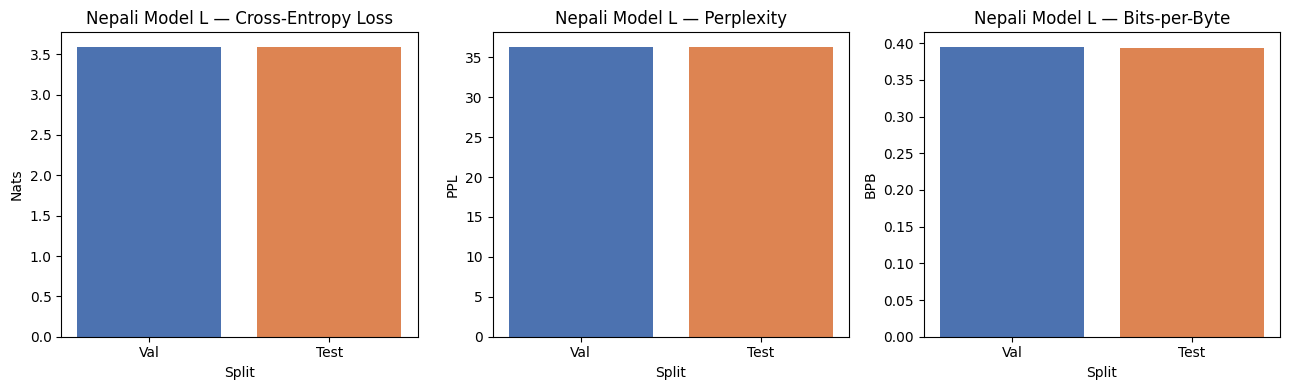

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
labels = ['Val', 'Test']
metrics_pairs = [val_metrics, test_metrics]

for ax, key, title, ylabel in zip(
    axes,
    ['loss_nats', 'perplexity', 'bpb'],
    ['Cross-Entropy Loss', 'Perplexity', 'Bits-per-Byte'],
    ['Nats', 'PPL', 'BPB']
):
    ax.bar(labels, [m[key] for m in metrics_pairs], color=['#4C72B0', '#DD8452'])
    ax.set_title(f'Nepali Model L — {title}')
    ax.set_xlabel('Split')
    ax.set_ylabel(ylabel)

plt.tight_layout()
plt.show()


## Generation

Greedy decoding + temperature sampling (0.5 / 1.0 / 1.5) from held-out prefixes drawn
from `test.txt`. Each line is split into a prefix (first half) and a reference
continuation (second half) for use as the BLEU/chrF/ROUGE-L reference below.


In [17]:
import random as _random

N_SAMPLES = 30
PREFIX_TOKENS = 32
MAX_NEW_TOKENS = 64

_random.seed(SEED)
with open(f'{SPLIT_DIR}/test.txt', encoding='utf-8') as f:
    test_lines = [l.strip() for l in f if len(l.strip()) > 20]

sample_lines = _random.sample(test_lines, min(N_SAMPLES, len(test_lines)))

@torch.no_grad()
def generate(prefix_ids, max_new_tokens, temperature=None):
    """temperature=None -> greedy decoding."""
    ids = torch.tensor([prefix_ids], dtype=torch.long, device=device)
    for _ in range(max_new_tokens):
        ids_cond = ids[:, -CONTEXT_LEN:]
        logits, _ = model(ids_cond)
        next_logits = logits[0, -1]
        if temperature is None:
            next_id = torch.argmax(next_logits).item()
        else:
            probs = F.softmax(next_logits / temperature, dim=-1)
            next_id = torch.multinomial(probs, 1).item()
        ids = torch.cat([ids, torch.tensor([[next_id]], device=device)], dim=1)
    return ids[0].tolist()

generations = {'greedy': [], 'temp_0.5': [], 'temp_1.0': [], 'temp_1.5': []}
references = []
prefixes_text = []

for line in sample_lines:
    full_ids = encode_text(line)
    if len(full_ids) < PREFIX_TOKENS + 5:
        continue
    prefix_ids = full_ids[:PREFIX_TOKENS]
    ref_ids = full_ids[PREFIX_TOKENS:PREFIX_TOKENS + MAX_NEW_TOKENS]

    prefixes_text.append(decode(prefix_ids))
    references.append(decode(ref_ids))

    for key, temp in [('greedy', None), ('temp_0.5', 0.5), ('temp_1.0', 1.0), ('temp_1.5', 1.5)]:
        out_ids = generate(prefix_ids, MAX_NEW_TOKENS, temperature=temp)
        continuation_ids = out_ids[len(prefix_ids):]
        generations[key].append(decode(continuation_ids))

print(f"Generated {len(references)} samples per setting.")
print("\nExample:")
print("Prefix:   ", prefixes_text[0])
print("Reference:", references[0])
print("Greedy:   ", generations['greedy'][0])


Generated 23 samples per setting.

Example:
Prefix:    सरकारले मधेश प्रदेशको राजधानी जनकपुरधाममा मिटरब्याज जाँचबुझ कार्यालय उद्घाटन गर्दै छ। नेपाल सरकारका उपप्रधानमन्त्री एवं गृहमन्त्री नारायणकाजी श्रेष्ठले आइतबार बिहान जनकपुरमा कार्यालय उद्घाटन गर्न लागेका हुन्। त्यसका लागि
Reference:  गृहमन्त्री श्रेष्ठ बिहानै जनकपुर पुगिसकेका छन्। सरकारले गत चैत २० गते मिटरब्याज पीडितका समस्या समाधान गर्ने उद्देश्यले पूर्वन्यायाधीश गौरीबहादुर कार्कीको नेतृत्वमा अनुचित लेनदेन मिटरब्याज सम्बन्धी जाँचबुझ आयोग गठन गरेको थियो। तीन सदस्यीय आयोगमा उत्तमराज सुवेदी र गणेशबाबु अर्याल सदस्य छन्। आयोगलाई मिटरब्याज पीडितका समस्या छानबिन गरी प्रतिवेदन बुझाउन तीन महिनाको समय दिइएको
Greedy:     प्रधानमन्त्री पुष्पकमल दाहाल प्रचण्ड, नेकपा एमालेका अध्यक्ष केपी शर्मा ओली, नेकपा माओवादी केन्द्रका अध्यक्ष पुष्पकमल दाहाल प्रचण्ड, नेकपा एकीकृत समाजवादीका अध्यक्ष माधवकुमार नेपाल, जनता समाजवादी पार्टीका अध्यक्ष उपेन्द्र यादव, राष्ट्रिय जनमोर्चाका अध्यक्ष चित्रबहादुर केसी, जनता समाजवादी पार्टीका अध्यक्ष उपेन्द्र यादव, राष्ट्

## Generation quality: BLEU-4, chrF++, ROUGE-L

Computed with `sacrebleu` (BLEU-4, chrF++) and `rouge_score` (ROUGE-L). Note:
`use_stemmer=False` — English stemming applied to Devanagari text silently mangles
every string and is a likely cause of a previous ROUGE-L=0.000 result on the Hindi run;
we also skip any empty-hypothesis pairs rather than silently scoring them 0.


In [18]:
import sacrebleu
from rouge_score import rouge_scorer

rouge = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False)

def compute_gen_metrics(hyps, refs):
    pairs = [(h, r) for h, r in zip(hyps, refs) if h.strip() and r.strip()]
    if not pairs:
        return {'bleu4': 0.0, 'chrf++': 0.0, 'rougeL': 0.0, 'n_scored': 0}
    hyps_f, refs_f = zip(*pairs)

    bleu = sacrebleu.corpus_bleu(list(hyps_f), [list(refs_f)])
    chrf = sacrebleu.corpus_chrf(list(hyps_f), [list(refs_f)], word_order=2)  # chrF++
    rouge_scores = [rouge.score(r, h)['rougeL'].fmeasure for h, r in pairs]

    return {
        'bleu4': bleu.score,
        'chrf++': chrf.score,
        'rougeL': sum(rouge_scores) / len(rouge_scores),
        'n_scored': len(pairs),
    }

gen_quality = {}
for key in generations:
    gen_quality[key] = compute_gen_metrics(generations[key], references)
    print(key, '->', gen_quality[key])


greedy -> {'bleu4': 1.2196945115645383, 'chrf++': 13.543666827128337, 'rougeL': 0.0, 'n_scored': 23}
temp_0.5 -> {'bleu4': 1.5607628661778723, 'chrf++': 19.880330405064566, 'rougeL': 0.0, 'n_scored': 23}
temp_1.0 -> {'bleu4': 1.0644182911732107, 'chrf++': 19.265468674829624, 'rougeL': 0.0, 'n_scored': 23}
temp_1.5 -> {'bleu4': 0.14445293747207294, 'chrf++': 16.081354361115274, 'rougeL': 0.0, 'n_scored': 23}


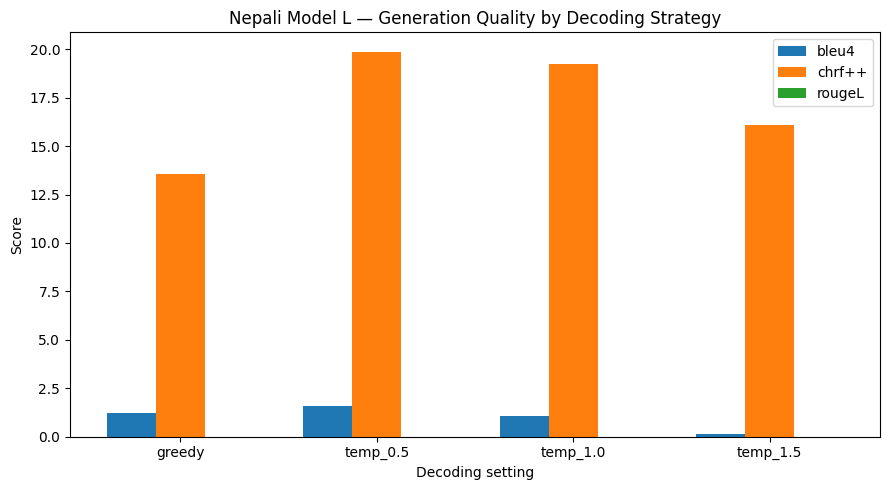

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
settings = list(gen_quality.keys())
width = 0.25
x = np.arange(len(settings))

for i, metric in enumerate(['bleu4', 'chrf++', 'rougeL']):
    vals = [gen_quality[s][metric] for s in settings]
    ax.bar(x + i * width, vals, width, label=metric)

ax.set_xticks(x + width)
ax.set_xticklabels(settings)
ax.set_xlabel('Decoding setting')
ax.set_ylabel('Score')
ax.set_title('Nepali Model L — Generation Quality by Decoding Strategy')
ax.legend()
plt.tight_layout()
plt.show()


## Diversity / fluency diagnostics

Repetition rate (fraction of repeated bigrams within a generation) and Distinct-1 /
Distinct-2 (unique unigram/bigram ratio) across all generated continuations per setting.


greedy -> {'repetition_rate': 0.6711953350616122, 'distinct_1': 0.22905525846702318, 'distinct_2': 0.3166515013648772}
temp_0.5 -> {'repetition_rate': 0.33513333589555316, 'distinct_1': 0.39814814814814814, 'distinct_2': 0.6283261802575107}
temp_1.0 -> {'repetition_rate': 0.021320837231902243, 'distinct_1': 0.721370604147881, 'distinct_2': 0.9585635359116023}
temp_1.5 -> {'repetition_rate': 0.0, 'distinct_1': 0.9078947368421053, 'distinct_2': 0.9990393852065321}


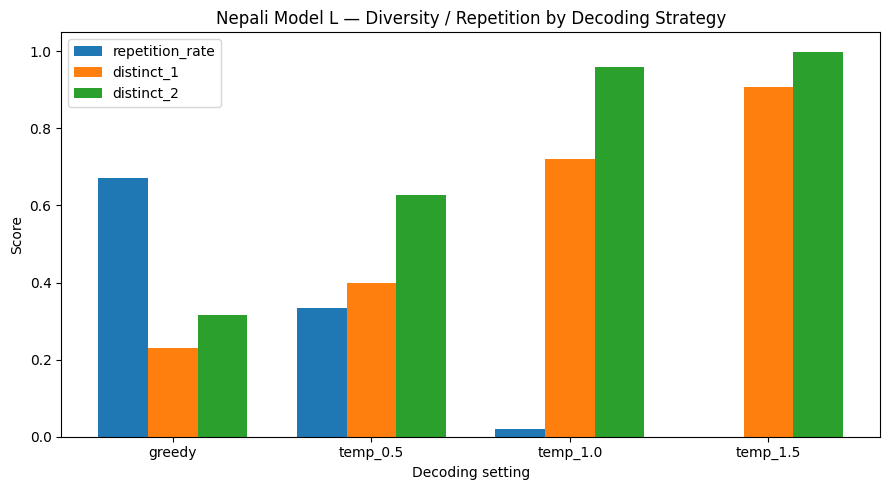

In [20]:
def repetition_rate(text):
    toks = text.split()
    if len(toks) < 2:
        return 0.0
    bigrams = list(zip(toks, toks[1:]))
    if not bigrams:
        return 0.0
    return 1 - len(set(bigrams)) / len(bigrams)

def distinct_n(texts, n):
    all_ngrams = []
    for t in texts:
        toks = t.split()
        all_ngrams.extend(zip(*[toks[i:] for i in range(n)]))
    if not all_ngrams:
        return 0.0
    return len(set(all_ngrams)) / len(all_ngrams)

diversity = {}
for key, texts in generations.items():
    diversity[key] = {
        'repetition_rate': sum(repetition_rate(t) for t in texts) / len(texts),
        'distinct_1': distinct_n(texts, 1),
        'distinct_2': distinct_n(texts, 2),
    }
    print(key, '->', diversity[key])

fig, ax = plt.subplots(figsize=(9, 5))
settings = list(diversity.keys())
width = 0.25
x = np.arange(len(settings))
for i, metric in enumerate(['repetition_rate', 'distinct_1', 'distinct_2']):
    vals = [diversity[s][metric] for s in settings]
    ax.bar(x + i * width, vals, width, label=metric)
ax.set_xticks(x + width)
ax.set_xticklabels(settings)
ax.set_xlabel('Decoding setting')
ax.set_ylabel('Score')
ax.set_title('Nepali Model L — Diversity / Repetition by Decoding Strategy')
ax.legend()
plt.tight_layout()
plt.show()


## Attention analysis

Heatmaps, per-head entropy, and mean attention distance for an early layer (block 0)
and a late layer (block 5), on one representative held-out sentence.


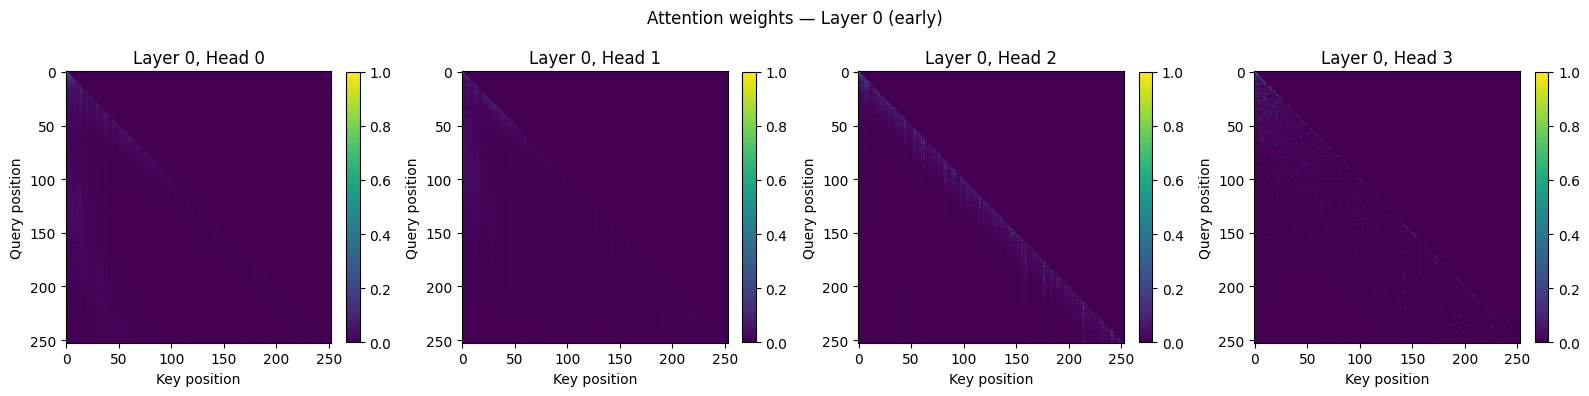

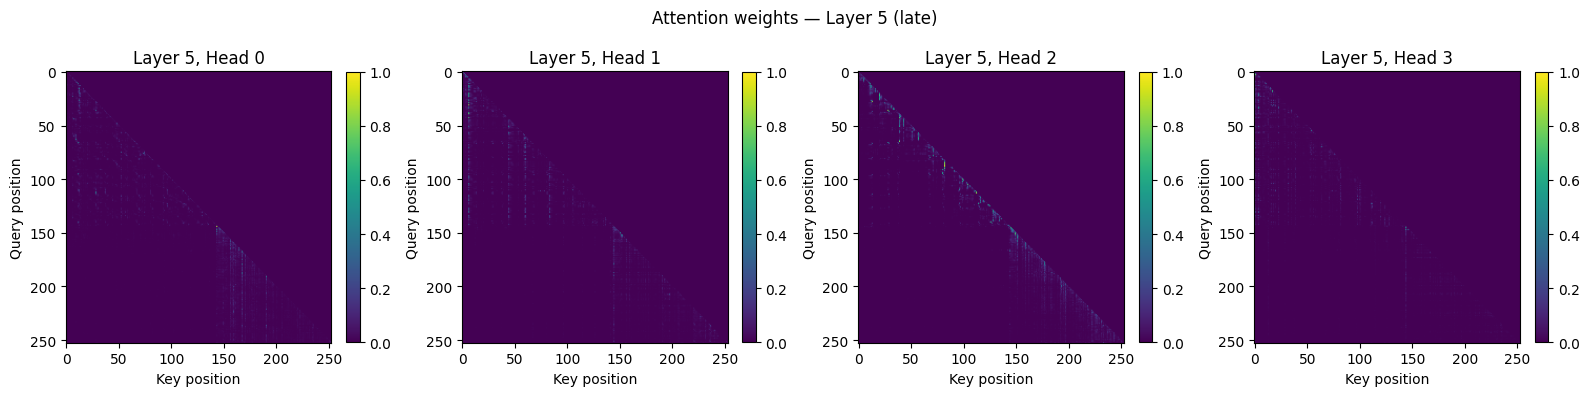

In [21]:
EARLY_LAYER = 0
LATE_LAYER = config['n_layers'] - 1

sample_text = sample_lines[0]
sample_ids = encode_text(sample_text)[:CONTEXT_LEN]
sample_tokens = [ID_TO_TOK.get(i, '?') for i in sample_ids]

with torch.no_grad():
    x = torch.tensor([sample_ids], dtype=torch.long, device=device)
    _, attn_maps = model(x, return_attn_layers={EARLY_LAYER, LATE_LAYER})

def plot_attention_heads(attn, layer_idx, n_heads_to_show=4):
    attn = attn[0].cpu().numpy()  # (n_heads, T, T)
    n_heads_to_show = min(n_heads_to_show, attn.shape[0])
    fig, axes = plt.subplots(1, n_heads_to_show, figsize=(4 * n_heads_to_show, 4))
    if n_heads_to_show == 1:
        axes = [axes]
    for h in range(n_heads_to_show):
        im = axes[h].imshow(attn[h], cmap='viridis', aspect='auto')
        axes[h].set_title(f'Layer {layer_idx}, Head {h}')
        axes[h].set_xlabel('Key position')
        axes[h].set_ylabel('Query position')
        fig.colorbar(im, ax=axes[h], fraction=0.046)
    plt.suptitle(f'Attention weights — Layer {layer_idx} (early)' if layer_idx == EARLY_LAYER
                 else f'Attention weights — Layer {layer_idx} (late)')
    plt.tight_layout()
    plt.show()

plot_attention_heads(attn_maps[EARLY_LAYER], EARLY_LAYER)
plot_attention_heads(attn_maps[LATE_LAYER], LATE_LAYER)


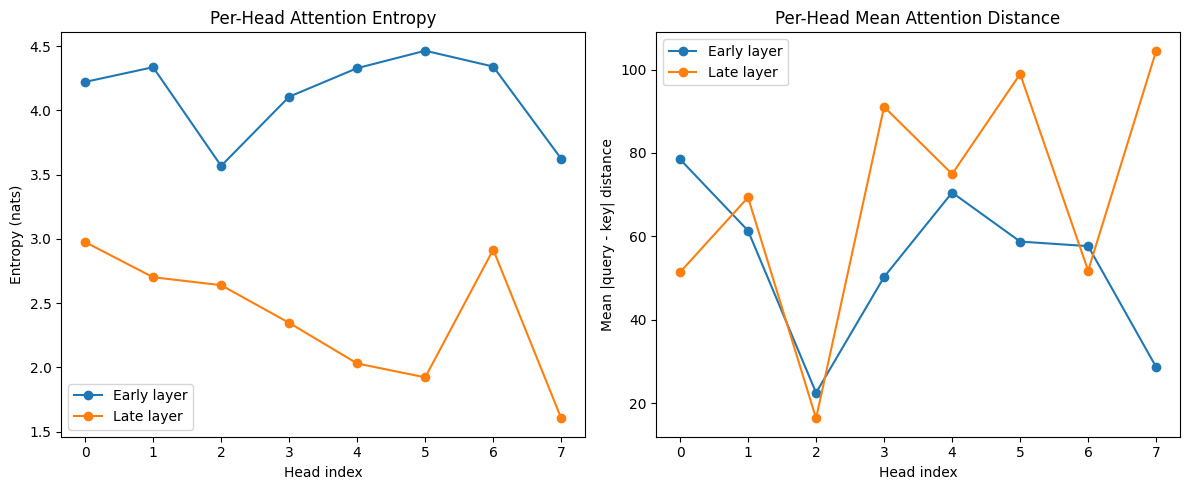

Sentence used: सरकारले मधेश प्रदेशको राजधानी जनकपुरधाममा मिटरब्याज जाँचबुझ कार्यालय उद्घाटन गर्दै छ। नेपाल सरकारका उपप्रधानमन्त्री एवं गृहमन्त्री नारायणकाजी श्रेष्ठले आइतबार बिहान जनकपुरमा कार्यालय उद्घाटन गर्न लागेका हुन्। त्यसका लागि गृहमन्त्री श्रेष्ठ बिहानै जनकपुर पुगिसकेका छन्। सरकारले गत चैत २० गते मिटरब्याज पीडितका समस्या समाधान गर्ने उद्देश्यले पूर्वन्यायाधीश गौरीबहादुर कार्कीको नेतृत्वमा अनुचित लेनदेन मिटरब्याज सम्बन्धी जाँचबुझ आयोग गठन गरेको थियो। तीन सदस्यीय आयोगमा उत्तमराज सुवेदी र गणेशबाबु अर्याल सदस्य छन्। आयोगलाई मिटरब्याज पीडितका समस्या छानबिन गरी प्रतिवेदन बुझाउन तीन महिनाको समय दिइएको छ। जनकपुरमा आज आयोगको केन्द्रीय कार्यालय उद्घाटनपछि पीडितबाट उजुरी लिन सुरु गरिने संयोजक कार्कीले जानकारी दिए। आजबाट १५ दिन सम्म आयोगमा उजुरी गर्न सकिने आयोगले जनाएको छ। आयोगले चार दिनअघि नै विज्ञप्ति जारी गरी सबै पीडितलाई उजुरी दिन आह्वान गरिसकेको छ। काठमाडौं । प्रधानमन्त्री केपी शर्मा ओली र नेपाल विद्युत प्राधिकरणका कार्यकारी निर्देशक कुलमान घिसिङबीच विवाद नेपालीमा उखानै छ- हात्ती आयो,

In [22]:
def attention_entropy(attn):
    # attn: (n_heads, T, T) -- entropy per query position, averaged over positions/heads
    eps = 1e-9
    ent = -(attn * torch.log(attn + eps)).sum(dim=-1)  # (n_heads, T)
    return ent.mean(dim=-1)  # (n_heads,)

def mean_attention_distance(attn):
    n_heads, T, _ = attn.shape
    positions = torch.arange(T, device=attn.device)
    q_pos = positions.view(1, T, 1)
    k_pos = positions.view(1, 1, T)
    dist = (q_pos - k_pos).abs().float()
    weighted = (attn * dist).sum(dim=-1)  # (n_heads, T)
    return weighted.mean(dim=-1)  # (n_heads,)

layer_stats = {}
for layer_idx in [EARLY_LAYER, LATE_LAYER]:
    a = attn_maps[layer_idx][0]
    layer_stats[layer_idx] = {
        'entropy': attention_entropy(a).cpu().numpy(),
        'distance': mean_attention_distance(a).cpu().numpy(),
    }

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, metric, title, ylabel in zip(
    axes, ['entropy', 'distance'],
    ['Per-Head Attention Entropy', 'Per-Head Mean Attention Distance'],
    ['Entropy (nats)', 'Mean |query - key| distance']
):
    for layer_idx, label in [(EARLY_LAYER, 'Early layer'), (LATE_LAYER, 'Late layer')]:
        vals = layer_stats[layer_idx][metric]
        ax.plot(range(len(vals)), vals, marker='o', label=label)
    ax.set_title(title)
    ax.set_xlabel('Head index')
    ax.set_ylabel(ylabel)
    ax.legend()
plt.tight_layout()
plt.show()

print("Sentence used:", sample_text)
print("\nHigh entropy = diffuse attention (content-based / global);")
print("Low entropy + low mean distance = sharp, local/positional attention.")


## Your discussion (fill in for the report)

- Which heads in the early vs. late layer look local/positional (low entropy, low mean
  distance) vs. content-based (higher entropy, longer-range)?
- How do BLEU/chrF/ROUGE-L trend across greedy → temp 0.5 → 1.0 → 1.5? Does higher
  temperature trade quality for diversity as expected (check Distinct-1/2 above)?
- If evaluating the 30k-step checkpoint: how do these numbers compare once the real
  final checkpoint is evaluated?
